# 🔭 Lab 01: Trace-Based Evaluation Setup

## Module 01 — Modern AI Evaluation Foundations 🧱

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/1_TraceBasedEvalSetup_STUDENT.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 20–25 min core · +25–40 min extended |
| 🎚️ **Level** | Foundations: no prior tracing experience needed |
| 🔑 **Accounts** | Free Langfuse Cloud account (Task 1). OpenAI key optional (Task 11 only) |
| 🧰 **You'll use** | `langfuse` v4 SDK · `pandas` · (optional) `openai` |
| 🏁 **You'll leave with** | Traced interactions, scores attached to traces, and a root-caused RAG bug |

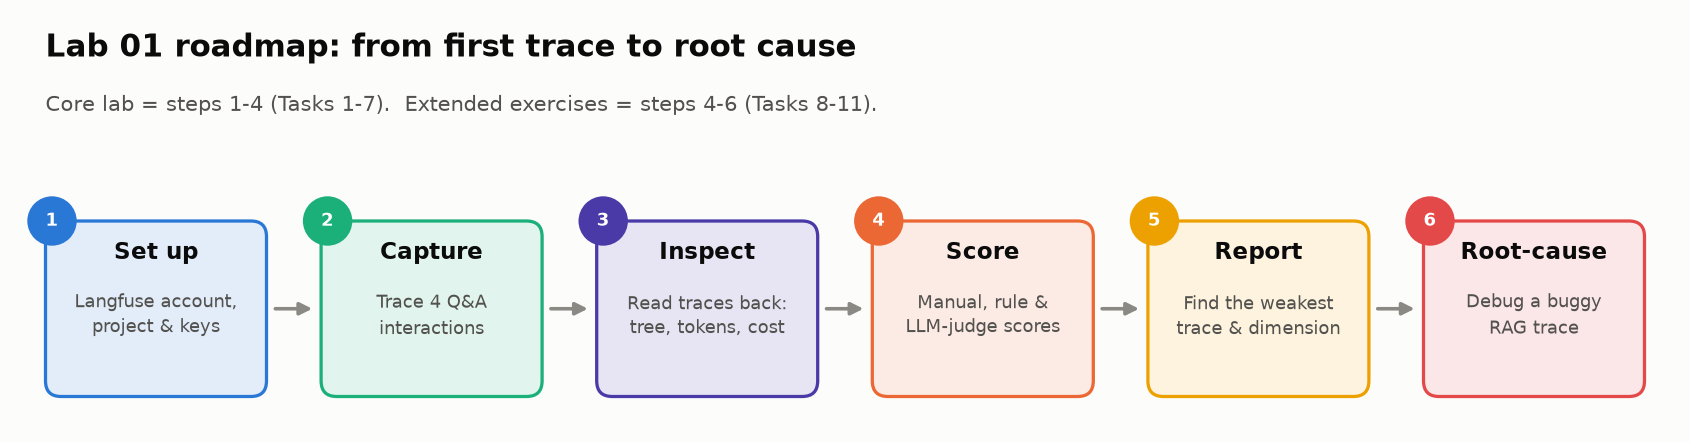

<sub>🖼️ *Your path through this lab*</sub>

---

## 🧭 Overview

In this lab you will configure **Langfuse** to capture traces from LLM interactions, then use those traces to evaluate the system in ways that are impossible when you only look at model outputs.

By the end of this lab you will have:
- A working Langfuse tracing setup
- Multiple traced LLM interactions (single-step and multi-step)
- Hands-on experience reading trace data back programmatically
- Manual, rule-based, and (optionally) LLM-as-judge scores attached to traces
- A small score report that shows where the assistant is weakest

## 🎯 Learning Objectives

1. Configure Langfuse tracing for an LLM application
2. Capture traces including prompts, responses, latency, and token usage
3. Explain what trace-based evaluation captures that output-only evaluation misses
4. Design evaluation criteria using trace data
5. Attach evaluation scores to traces programmatically
6. Use a trace to find the *root cause* of a bad answer in a multi-step pipeline

## 📋 Prerequisites

- Python proficiency
- Basic understanding of LLM APIs (prompts, completions)
- Familiarity with ML evaluation concepts (accuracy, precision, recall)

## ⏱️ Estimated Time

| Part | Tasks | Time |
|------|-------|------|
| Core lab | Tasks 1–7 | 20–25 min |
| Extended exercises | Tasks 8–11 | 25–40 min |

## 🎬 Scenario

You are an ML engineer setting up an evaluation framework for a customer-facing Q&A assistant that answers questions about a company's product documentation. Management wants to move beyond "does it sound right?" to rigorous, traceable evaluation. Your first step: get tracing working and understand what data it gives you.

> **Tested with:** `langfuse` Python SDK **v4.x** (OpenTelemetry-based). If you have an older notebook using `langfuse.trace(...)`, that API no longer exists — see the Troubleshooting table at the end.

---

## 🔑 Understanding Langfuse and Traces: A Beginner's Guide

### What is Langfuse?

**Langfuse** is an open-source **observability and evaluation platform** for LLM applications. Think of it as a monitoring dashboard plus debugger for AI apps.

When you build with LLMs you need to:
- See what prompts are being sent
- Track what responses come back
- Measure how long things take and what they cost
- Identify errors and issues
- Evaluate quality over time

**Analogy:** If you have used CloudWatch or Datadog for traditional services, Langfuse is the equivalent for LLM applications, with AI-specific features like token tracking, cost calculation and evaluation scores.

### What is a Trace?

A **trace** is the complete record of one request to your LLM application, from the moment the user asks until they get an answer.

| Component | What It Captures | Why It Matters |
|-----------|------------------|----------------|
| **Input** | The user's question or prompt | Understand what users are asking |
| **Output** | The model's response | See what your AI actually said |
| **Latency** | How long each step took | User experience, SLAs |
| **Token Usage** | Tokens consumed per LLM call | Cost (you pay per token) |
| **Model Info** | Which model was used (e.g., `gpt-4o-mini`) | Compare models / versions |
| **Metadata & Tags** | Custom labels you add | Filter and slice traces |
| **Timestamps** | When each step started and ended | Find the slow step |

### Trace Hierarchy: Traces, Spans, and Generations

Real LLM applications usually have multiple steps, so a trace is a **tree of observations**:

```
TRACE  (one user request)
 └── SPAN: handle-request            ← root observation: the whole request
      ├── RETRIEVER: search-docs     ← a step (e.g. vector search)
      └── GENERATION: llm-completion ← the actual LLM call
```

| Observation type | Use it for |
|------------------|-----------|
| **Span** | A generic unit of work (a function, a pipeline stage) |
| **Generation** | An LLM call — carries `model`, token usage and cost |
| **Retriever / Tool / Agent / Evaluator / Guardrail** | Specialised span types that make the UI easier to read |

The **trace** itself is just the container; in the SDK you never create it directly. The first (outermost) observation you open becomes the **root**, and Langfuse creates the trace around it.

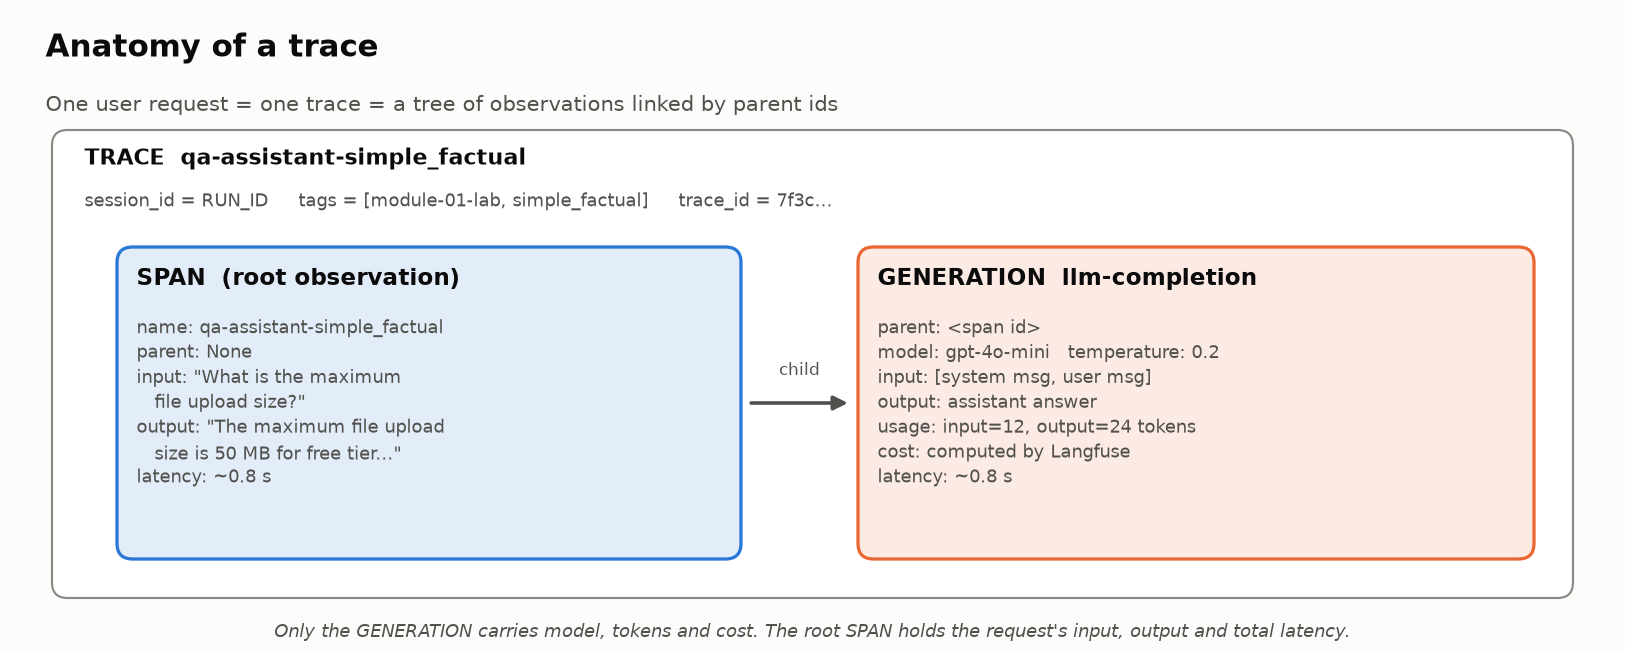

<sub>🖼️ *A trace is a tree: the root span holds the request, the generation holds model, tokens and cost*</sub>

### What a trace in *this* lab looks like

For the question *"What is the maximum file upload size?"* the code in Task 3 produces:

```
📦 TRACE  qa-assistant-simple_factual       tags: [module-01-lab, simple_factual]
│   input:  "What is the maximum file upload size?"
│   output: "The maximum file upload size is 50 MB for free-tier..."
│
└── 🔹 SPAN  qa-assistant-simple_factual     (root observation, ~0.8 s)
     │
     └── 📄 GENERATION  llm-completion       (~0.8 s)
          model:  gpt-4o-mini
          usage:  input=12, output=24 tokens
          cost:   computed by Langfuse from the model price table
```

> **Why both a span and a generation for a single LLM call?** Strictly you could make the generation the root. We wrap it in a span on purpose: the moment you add retrieval, validation or a second LLM call (Task 10), they slot in as siblings under the same root without changing the structure.

### Why Do We Use Traces for Evaluation?

**Output-only evaluation misses:**
- Was it fast or slow?
- Did it use far too many tokens (expensive)?
- Which model or prompt version produced it?
- Did an *intermediate* step (retrieval, a tool call) fail, even though the final text sounds fine?

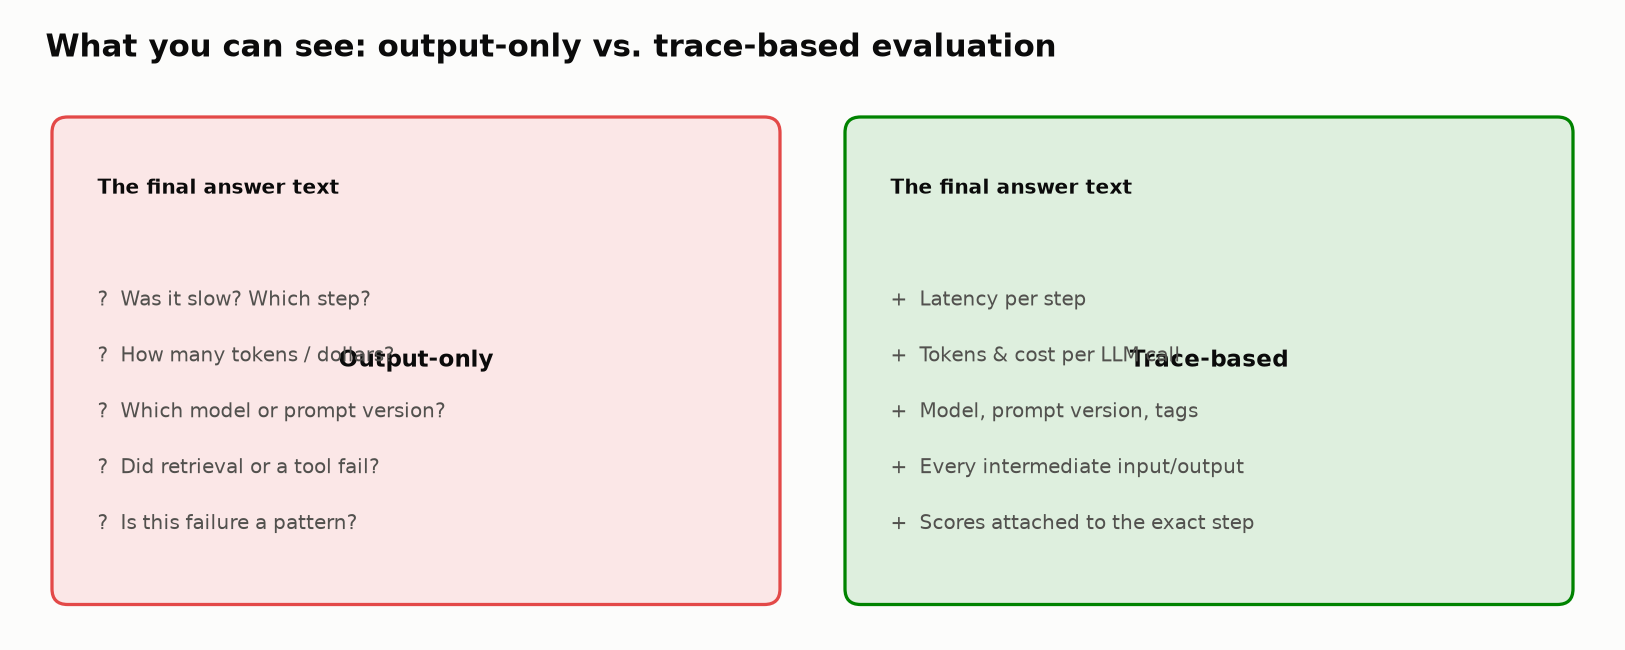

<sub>🖼️ *What each style of evaluation can actually see*</sub>

**With traces you can:**
1. **Attach scores** directly to the interaction (or the specific step) they evaluate
2. **Filter and compare** across tags, models, versions, users
3. **Trend** quality over time
4. **Debug** failures with full context
5. **Analyse cost** per request type

### Quick Vocabulary Reference

| Term | Definition |
|------|------------|
| **Trace** | A complete record of one user interaction |
| **Observation** | Anything inside a trace: span, generation, retriever, tool, … |
| **Span** | A logical step or operation within a trace |
| **Generation** | An LLM API call (has model, tokens, cost) |
| **Score** | An evaluation result attached to a trace or observation (numeric, boolean or categorical) |
| **Session** | A group of related traces (e.g. one chat conversation — or, in this lab, one notebook run) |
| **Flush** | Send all buffered data to Langfuse now instead of in the background |
| **Ingestion delay** | Data is written asynchronously; it can take a few seconds before the API can return it |

---

## 🛠️ Task 1: Set Up Your Langfuse Account, Project and Environment

Each person works in their own Langfuse project so that traces stay clean and easy to debug.

### Step 1 — Create a Langfuse account

Langfuse Cloud has two **regions**. Pick one and remember it — your API keys only work against the region you signed up in.

| Region | Sign-up / host URL |
|--------|--------------------|
| 🇺🇸 US | https://us.cloud.langfuse.com |
| 🇪🇺 EU | https://cloud.langfuse.com |

Sign up with Google, GitHub, or email.

### Step 2 — Create an organization

On the **Organizations** page click **+ New Organization** and give it a name such as `advanced-model-course`.

### Step 3 — Create a project

Inside the organization click **New Project**, e.g. `trace-eval-lab`.

💡 A project represents one application you want to observe (a chatbot, a RAG pipeline, an agent).

### Step 4 — Create API keys

In the project go to **Settings → API Keys → Create new API keys** (note: "class key"). Copy:

- Public Key (`pk-lf-...`)
- Secret Key (`sk-lf-...`) — **shown only once**, save it somewhere safe

> ⚠️ **Never paste real keys into a notebook you share.** Anyone with the notebook can write to (and read from) your project. In Task 2 you'll enter keys through Colab Secrets or a hidden prompt instead. If keys have ever been committed or shared, delete them in Langfuse and create new ones.

### Step 5 — Install dependencies

Run the next two cells. The install takes about a minute.

In [ ]:
%%capture
# ============================================================================
# PACKAGE INSTALLATION
# ============================================================================
#   - langfuse: Langfuse Python SDK (v4 is built on OpenTelemetry)
#   - openai:   Only needed for the optional LLM-as-judge exercise (Task 11)
#   - pandas:   For the score report in Task 9 (pre-installed on Colab)
#
# We pin langfuse to the v4 major version so that the API used in this
# notebook does not change underneath you mid-course.
# ============================================================================

!pip install -U "langfuse>=4,<5" openai pandas

In [ ]:
# ============================================================================
# STANDARD LIBRARY IMPORTS
# ============================================================================
import os
import time
import uuid
from getpass import getpass

import langfuse as _lf
print(f"✅ Imports OK — langfuse SDK version {_lf.__version__}")
if not _lf.__version__.startswith("4."):
    print("⚠️  This notebook targets langfuse v4.x. If you see AttributeErrors later, "
          "re-run the install cell and then Runtime → Restart session.")

### Checkpoint ✅
You should see `✅ Imports OK — langfuse SDK version 4.x.x`.

> **Colab tip:** if you had already imported an older `langfuse` in this session before installing, use **Runtime → Restart session** and run from the top. Python keeps the old version in memory until restart.

---

## 🔌 Task 2: Configure the Langfuse Connection

### Goal
Initialise the Langfuse client and verify it can talk to the backend.

### How credentials are loaded (in order)
1. **Colab Secrets** — click the 🔑 icon in Colab's left sidebar and add `LANGFUSE_PUBLIC_KEY` and `LANGFUSE_SECRET_KEY` (toggle *Notebook access* on). Recommended: you set them once and they never appear in the notebook.
2. **Existing environment variables** — if you're running locally with a `.env`.
3. **Hidden prompt** — otherwise the cell asks you to paste them (input is not echoed or saved).

Set `LANGFUSE_REGION` below to match where you created your account.

In [ ]:
# ============================================================================
# LANGFUSE CONFIGURATION
# ============================================================================
# The SDK reads three environment variables:
#   LANGFUSE_PUBLIC_KEY  (pk-lf-...)  identifies your project
#   LANGFUSE_SECRET_KEY  (sk-lf-...)  authenticates requests — treat like a password
#   LANGFUSE_BASE_URL                 which Langfuse server to talk to
#                                     (LANGFUSE_HOST is the older name; we set both)
# ============================================================================

LANGFUSE_REGION = "US"   # 👈 "US" or "EU" — must match the region you signed up in

HOSTS = {
    "US": "https://us.cloud.langfuse.com",
    "EU": "https://cloud.langfuse.com",
}

def _load_secret(name: str) -> str:
    """Colab Secrets → existing env var → hidden prompt."""
    try:
        from google.colab import userdata          # only exists on Colab
        value = userdata.get(name)
        if value:
            print(f"  🔑 {name}: loaded from Colab Secrets")
            return value
    except Exception:
        pass
    if os.environ.get(name):
        print(f"  🔑 {name}: loaded from environment")
        return os.environ[name]
    return getpass(f"Paste your {name}: ").strip()

os.environ["LANGFUSE_PUBLIC_KEY"] = _load_secret("LANGFUSE_PUBLIC_KEY")
os.environ["LANGFUSE_SECRET_KEY"] = _load_secret("LANGFUSE_SECRET_KEY")
os.environ["LANGFUSE_BASE_URL"] = HOSTS[LANGFUSE_REGION.upper()]
os.environ["LANGFUSE_HOST"] = os.environ["LANGFUSE_BASE_URL"]

# Quick sanity checks that catch the two most common copy/paste mistakes
assert os.environ["LANGFUSE_PUBLIC_KEY"].startswith("pk-lf-"), "Public key should start with pk-lf-"
assert os.environ["LANGFUSE_SECRET_KEY"].startswith("sk-lf-"), "Secret key should start with sk-lf- (did you swap them?)"
print(f"\n🌍 Using Langfuse host: {os.environ['LANGFUSE_BASE_URL']}")

In [ ]:
# ============================================================================
# INITIALISE THE CLIENT AND CHECK THE CONNECTION
# ============================================================================
# get_client() returns a client configured from the environment variables
# above. auth_check() makes one real request to confirm the keys + host work.
# It returns True on success and raises an exception otherwise.
# ============================================================================

from langfuse import get_client, propagate_attributes

langfuse = get_client()

try:
    ok = langfuse.auth_check()
except Exception as e:
    ok = False
    print(f"❌ {type(e).__name__}: {e}")

if ok:
    print("✅ Langfuse connection successful!")
else:
    print("\nCheck that:")
    print("  • LANGFUSE_REGION matches the region you signed up in (US vs EU)")
    print("  • the public and secret keys are from the SAME project and weren't swapped")
    raise SystemExit("Fix the connection before continuing.")

### Run ID — keeping your traces separate between runs

Every time you re-run this notebook you create new traces. To read back **only this run's** traces later, we generate a `RUN_ID` and attach it to every trace as the **session id** and a **tag**. In the Langfuse UI you can then open *Sessions* and see one run grouped together.

In [ ]:
# ============================================================================
# RUN ID + SMALL HELPERS USED THROUGHOUT THE LAB
# ============================================================================
import json
from httpx import ReadTimeout
from langfuse.api import NotFoundError

RUN_ID = f"lab01-{uuid.uuid4().hex[:8]}"
print(f"🏷️  RUN_ID for this notebook run: {RUN_ID}")


def wait_for(fetch, *, ready=lambda result: True, what="data", timeout=120, interval=5):
    """
    Call `fetch()` until it succeeds and `ready(result)` is True.

    WHY THIS EXISTS: Langfuse ingests data asynchronously. Right after
    flush() the API may return 404 (NotFoundError) or an empty list for a
    few seconds. Querying immediately is the #1 cause of errors in this lab.
    """
    deadline = time.time() + timeout
    while True:
        try:
            result = fetch()
            if ready(result):
                return result
            reason = "not fully indexed yet"
        except NotFoundError:
            reason = "not found yet (still ingesting)"
        except ReadTimeout:
            reason = "request timed out"
        if time.time() > deadline:
            raise TimeoutError(
                f"Gave up waiting for {what} after {timeout}s. "
                "Check the Langfuse UI — if the data is there, just re-run this cell."
            )
        print(f"  ⏳ {what}: {reason} — retrying in {interval}s...")
        time.sleep(interval)


# ----------------------------------------------------------------------------
# READING DATA BACK: Observations API v2 + Scores API v3
# ----------------------------------------------------------------------------
# Langfuse organizations created on/after Sept 16, 2026 can NOT use the legacy
# read endpoints (langfuse.api.trace.list / trace.get / scores.get_many) —
# they fail with HTTP 410 LEGACY_API_UNAVAILABLE_FOR_NEW_ORGANIZATION.
# Everything in this lab therefore reads through:
#   langfuse.api.observations.get_many(...)    → GET /api/public/v2/observations
#   langfuse.api.scores_v3.get_many_v3(...)    → GET /api/public/v3/scores
#
# A "trace" is rebuilt from its observations: the ROOT observation carries the
# request's input/output/latency, and every observation carries trace_name/tags.
# ----------------------------------------------------------------------------

# Field groups for the observations API. If you leave `fields` out you only get
# ids/names/types — NOT input, output, model, token usage or tags.
OBS_FIELDS = "core,basic,io,metadata,model,usage,metrics,trace_context"


def get_observations(trace_id, obs_type=None, expected=1):
    """Fetch the observations of one trace, waiting for ingestion if needed."""
    return wait_for(
        lambda: langfuse.api.observations.get_many(
            trace_id=trace_id, type=obs_type, fields=OBS_FIELDS, limit=100
        ),
        ready=lambda r: len(r.data) >= expected,
        what=f"observations for {trace_id[:8]}…",
    ).data


def summarize_trace(observations):
    """Rebuild a trace-level summary from a trace's observations."""
    root = next(o for o in observations
                if o.is_root_observation or o.parent_observation_id is None)
    return {
        "trace_id": root.trace_id,
        "name": root.trace_name or root.name,
        "tags": root.tags or [],
        "session_id": root.session_id,
        "input": as_json(root.input),
        "output": as_json(root.output),
        "metadata": root.metadata or {},
        "latency": root.latency,
        "cost": sum(o.total_cost or 0 for o in observations),
        "start_time": root.start_time,
        "root": root,
        "observations": observations,
    }


def get_trace(trace_id, expected=2):
    return summarize_trace(get_observations(trace_id, expected=expected))


def get_scores(trace_id, expected=1):
    """All scores attached to a trace (fields='details' adds the comment)."""
    return wait_for(
        lambda: langfuse.api.scores_v3.get_many_v3(
            trace_id=trace_id, fields="details,subject", limit=100
        ),
        ready=lambda r: len(r.data) >= expected,
        what=f"scores for {trace_id[:8]}…",
    ).data


def score_number(s):
    """Scores v3 returns bool for BOOLEAN, float for NUMERIC, str for CATEGORICAL."""
    if isinstance(s.value, bool):
        return float(s.value)
    return float(s.value) if isinstance(s.value, (int, float)) else None


def as_json(value):
    """The observations API returns input/output as raw JSON strings. Decode them."""
    if isinstance(value, str):
        try:
            return json.loads(value)
        except ValueError:
            return value
    return value


def token_counts(usage):
    """Langfuse stores usage as {'input': n, 'output': m, 'total': n+m}."""
    usage = usage or {}
    inp = usage.get("input", usage.get("input_tokens", 0)) or 0
    out = usage.get("output", usage.get("output_tokens", 0)) or 0
    return int(inp), int(out)

print("✅ Helpers ready")

### Checkpoint ✅
You should see `✅ Langfuse connection successful!`, a `RUN_ID`, and `✅ Helpers ready`.

| If you see… | Do this |
|---|---|
| `UnauthorizedError` / 401 | Keys wrong, swapped, or from another project |
| Connection error / 401 with correct keys | Region mismatch — switch `LANGFUSE_REGION` |
| `AssertionError: ...should start with sk-lf-` | You pasted the keys into the wrong prompts |

---

## 📡 Task 3: Capture Traces from LLM Interactions

### Goal
Create four traced interactions for the product Q&A assistant. We use **simulated responses** so the lab runs without an OpenAI key and everyone gets the same data. The tracing code is identical to what you'd write around a real LLM call.

### What the code does for each interaction

```
propagate_attributes(...)            ← trace name, tags, session, metadata
 └── span   "qa-assistant-<name>"    ← root observation
      └── generation "llm-completion"   ← the (simulated) LLM call
            time.sleep(latency)         ← happens INSIDE the generation,
                                          so Langfuse measures it as the
                                          LLM call's latency
```

### Three v4 SDK details worth knowing

1. **`start_as_current_observation(...)`** opens an observation and makes it "current", so anything opened inside the `with` block becomes its child.
2. **Trace-level attributes** (name, tags, session, metadata) are set with **`propagate_attributes(...)`**, not on the span. In v4 a span's `metadata=` stays on the span only.
3. **The root observation *is* the request.** Its input/output/latency are what you read back as "the trace's" input/output/latency, so we give the root span the user's question and the final answer. (Older examples call `set_trace_io(...)`; it's deprecated and not needed.)

In [ ]:
# ============================================================================
# SIMULATED Q&A INTERACTIONS — OUR TEST DATASET
# ============================================================================
# Each interaction has:
#   name               identifier for the scenario
#   user               the user's question (input)
#   assistant          the assistant's answer (output)
#   expected_behavior  what a GOOD assistant should do here — this is a tiny
#                      "ground truth" label we'll use for automatic checks later
#   latency            simulated LLM response time in seconds
#   input_tokens / output_tokens   simulated token usage
#   model              which model "generated" it
# ============================================================================

QA_INTERACTIONS = [
    {
        "name": "simple_factual",
        "user": "What is the maximum file upload size?",
        "assistant": "The maximum file upload size is 50 MB for free-tier users and 500 MB for enterprise users.",
        "expected_behavior": "answer",
        "latency": 0.8, "input_tokens": 12, "output_tokens": 24, "model": "gpt-4o-mini",
    },
    {
        "name": "multi_step_reasoning",
        "user": "I upgraded to enterprise last week but I still can't upload files larger than 50 MB. What should I do?",
        "assistant": "Your account upgrade can take up to 24 hours to propagate. Please try logging out and back in. If the issue persists after 24 hours, contact support at support@example.com with your account ID.",
        "expected_behavior": "answer",
        "latency": 1.4, "input_tokens": 28, "output_tokens": 48, "model": "gpt-4o-mini",
    },
    {
        "name": "ambiguous_question",
        "user": "How do I delete everything?",
        "assistant": "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
        "expected_behavior": "clarify",      # ideally: ask what "everything" means first
        "latency": 1.1, "input_tokens": 8, "output_tokens": 42, "model": "gpt-4o-mini",
    },
    {
        "name": "out_of_scope",
        "user": "What's the weather like in Tokyo today?",
        "assistant": "I'm a product documentation assistant and can only help with questions about our platform. For weather information, please check a weather service.",
        "expected_behavior": "refuse",
        "latency": 0.6, "input_tokens": 10, "output_tokens": 28, "model": "gpt-4o-mini",
    },
]

print(f"Prepared {len(QA_INTERACTIONS)} simulated interactions:\n")
for i, it in enumerate(QA_INTERACTIONS, 1):
    q = it["user"] if len(it["user"]) <= 55 else it["user"][:55] + "…"
    print(f"  {i}. {it['name']:<22} expected={it['expected_behavior']:<8} \"{q}\"")

In [ ]:
# ============================================================================
# CREATE TRACED INTERACTIONS — THE CORE OF THIS LAB
# ============================================================================

trace_ids = {}   # name -> trace_id   (a dict is safer than a list: no index mix-ups)

for it in QA_INTERACTIONS:

    # --- Trace-level attributes ---------------------------------------------
    # Everything created inside this block inherits these attributes.
    with propagate_attributes(
        trace_name=f"qa-assistant-{it['name']}",
        session_id=RUN_ID,                               # groups this run's traces
        tags=["module-01-lab", it["name"]],              # filterable in UI & API
        metadata={"interaction_type": it["name"],
                  "expected_behavior": it["expected_behavior"]},
    ):
        # --- STEP 1: root span = the whole request ---------------------------
        with langfuse.start_as_current_observation(
            as_type="span",
            name=f"qa-assistant-{it['name']}",
            input=it["user"],                            # request input
            metadata={"interaction_type": it["name"],    # also kept on the root
                      "expected_behavior": it["expected_behavior"]},
        ) as root_span:

            # --- STEP 2: child generation = the LLM call -----------------------
            with langfuse.start_as_current_observation(
                as_type="generation",
                name="llm-completion",
                model=it["model"],
                model_parameters={"temperature": 0.2},
                input=[
                    {"role": "system", "content": "You answer questions about our product documentation only."},
                    {"role": "user", "content": it["user"]},
                ],
                metadata={"simulated": True},
            ) as generation:

                # In a real app: response = openai.chat.completions.create(...)
                time.sleep(it["latency"])            # ← measured as LLM latency

                # --- STEP 3: record the response + token usage ----------------
                # 'input'/'output' are Langfuse's canonical usage keys. Because
                # we also set `model`, Langfuse computes the cost automatically.
                generation.update(
                    output=it["assistant"],
                    usage_details={"input": it["input_tokens"],
                                   "output": it["output_tokens"]},
                )

            # --- STEP 4: request-level output -------------------------------------
            root_span.update(output=it["assistant"])

            trace_ids[it["name"]] = root_span.trace_id
            print(f"  ✅ Traced: {it['name']:<22} trace_id={root_span.trace_id}")

# --- STEP 5: flush --------------------------------------------------------------
# The SDK batches data in the background. flush() sends everything now —
# essential in notebooks and short scripts that may exit before a batch is sent.
langfuse.flush()

print(f"\n🎯 All {len(trace_ids)} interactions traced and flushed to Langfuse.")
first = trace_ids["simple_factual"]
print(f"🔗 Open one in the UI: {langfuse.get_trace_url(trace_id=first)}")

### Checkpoint ✅

```
  ✅ Traced: simple_factual         trace_id=...
  ✅ Traced: multi_step_reasoning   trace_id=...
  ✅ Traced: ambiguous_question     trace_id=...
  ✅ Traced: out_of_scope           trace_id=...

🎯 All 4 interactions traced and flushed to Langfuse.
🔗 Open one in the UI: https://...
```

Click the link. In the UI, check that:
- the trace shows a **span → generation** tree
- the generation shows `gpt-4o-mini`, token counts, a **cost**, and a latency close to 0.8 s
- **Sessions** (left sidebar) contains one session named after your `RUN_ID`

> If a trace looks empty for the first few seconds, refresh — ingestion is asynchronous.

---

## Task 4: 🔍 Think First — What Do Traces Capture That Outputs Alone Miss?

Imagine you only had the **outputs** (the four assistant answers). Now imagine you also have the **full traces** — latency per step, token usage, cost, model, timestamps, tags.

Answer in your own words in the next cell (2–3 minutes).

1. **Latency:** Interaction #2 took 1.4 s while #4 took 0.6 s. Would you know this from the outputs alone? Why does latency matter for evaluation — and why does it matter *which step* was slow?
2. **Token usage:** Interaction #3 used 8 input tokens but 42 output tokens (≈5× ratio). What might that ratio tell you?
3. **Debugging:** Suppose the assistant gave a wrong answer. With only the output, what can you diagnose? With a full trace, what extra information helps you find the root cause?
4. **Patterns at scale:** With 10,000 traces instead of 4, what could you detect from trace metadata that's invisible in outputs?

> There are no "right" answers shown here — use your reasoning. We'll discuss as a group.

### ✍️ Your Reflections

*(Double-click to edit.)*

1. **Latency:**

2. **Token ratio:**

3. **Debugging value:**

4. **Patterns at scale:**

---

## 🔬 Task 5: Explore Trace Data Structure

### Goal
Read your traces back through the API and inspect the **Trace → Observations** hierarchy, just as an automated evaluation pipeline would.

### The two read APIs you'll use

| Call | Endpoint | Returns |
|------|----------|---------|
| `langfuse.api.observations.get_many(trace_id=… / session_id=…, fields=…)` | Observations API **v2** | Observations — **ask for the field groups you need** (`io`, `model`, `usage`, `metrics`, `trace_context`, …) |
| `langfuse.api.scores_v3.get_many_v3(trace_id=…, fields="details")` | Scores API **v3** | Scores attached to a trace or its observations |

There is no "get trace" call in the current API. A trace is rebuilt from its observations: the **root** observation (the one with no parent) holds the request's input, output and latency, and every observation carries the trace's name and tags (`trace_context`). The `get_trace()` helper from Task 2 does exactly that.

> ⚠️ **Older notebooks and tutorials** use `langfuse.api.trace.list()`, `langfuse.api.trace.get()` and `langfuse.api.scores.get_many()`. Those hit legacy endpoints that return **HTTP 410 `LEGACY_API_UNAVAILABLE_FOR_NEW_ORGANIZATION`** for any Langfuse organization created on or after Sept 16, 2026, and Langfuse is removing them for everyone.

> Every read goes through the `wait_for(...)` helper, because freshly-flushed data may take a few seconds to become queryable.

In [ ]:
# ============================================================================
# LIST THIS RUN'S TRACES
# ============================================================================
# We ask the Observations API for every observation in this run's session
# (session_id=RUN_ID → only this notebook run, however many older traces your
# project has), then group them by trace_id to rebuild each trace.
# ============================================================================
from collections import defaultdict

langfuse.flush()

expected_obs = 2 * len(trace_ids)          # root span + generation per trace
session_obs = wait_for(
    lambda: langfuse.api.observations.get_many(
        session_id=RUN_ID, fields=OBS_FIELDS, limit=100),
    ready=lambda r: len(r.data) >= expected_obs,
    what="observations for this session",
).data

by_trace = defaultdict(list)
for o in session_obs:
    by_trace[o.trace_id].append(o)
traces = sorted((summarize_trace(obs) for obs in by_trace.values()),
                key=lambda t: t["start_time"])

print(f"Retrieved {len(session_obs)} observations → {len(traces)} traces for session {RUN_ID}\n")
print(f"{'Trace name':<36} {'Obs':>4} {'Latency':>8}  {'Cost ($)':>10}  Tags")
print("-" * 95)
for t in traces:
    latency = f"{t['latency']:.2f}s" if t["latency"] is not None else "n/a"
    print(f"{t['name']:<36} {len(t['observations']):>4} {latency:>8}  {t['cost']:>10.6f}  {t['tags']}")

In [ ]:
# ============================================================================
# DEEP DIVE INTO ONE TRACE
# ============================================================================
# Trace = container (name, tags, session, trace-level input/output, metadata)
# Observations = the steps inside it (root span + child generation here)
# ============================================================================

sample_trace_id = trace_ids["simple_factual"]

sample_trace = get_trace(sample_trace_id)          # rebuilt from observations
sample_observations = sample_trace["observations"]

print(f"=== Deep Dive: {sample_trace['name']} ===\n")
print(f"Trace ID:   {sample_trace['trace_id']}")
print(f"Session:    {sample_trace['session_id']}")
print(f"Tags:       {sample_trace['tags']}")
print(f"Input:      {sample_trace['input']}        ← from the root observation")
print(f"Output:     {sample_trace['output']}")
print(f"Latency:    {sample_trace['latency']}s")
print(f"Cost:       ${sample_trace['cost']:.8f}       ← sum over all observations")
print(f"\nObservations: {len(sample_observations)}")
print("-" * 60)

# Sort parent-first so the tree prints in order
for obs in sorted(sample_observations, key=lambda o: o.parent_observation_id is not None):
    indent = "  " if obs.parent_observation_id is None else "      └─ "
    print(f"\n{indent}📦 {obs.type}: {obs.name}")
    print(f"{' ' * 9}id:        {obs.id}")
    print(f"{' ' * 9}parent:    {obs.parent_observation_id}")
    print(f"{' ' * 9}model:     {obs.model}")
    print(f"{' ' * 9}latency:   {obs.latency}")
    print(f"{' ' * 9}usage:     {obs.usage_details}")
    print(f"{' ' * 9}cost:      {obs.total_cost}")
    print(f"{' ' * 9}input:     {str(as_json(obs.input))[:100]}")
    print(f"{' ' * 9}output:    {str(as_json(obs.output))[:100]}")
    print(f"{' ' * 9}metadata:  {obs.metadata}")

💡 **Notice:** the root span has `parent = None`; the generation's `parent` is the span's `id`. That parent pointer is the entire hierarchy — the UI tree is built from it. Also notice that only the **generation** has a model, usage and cost.

In [ ]:
# ============================================================================
# TOKEN, COST AND LATENCY ANALYSIS ACROSS TRACES
# ============================================================================
# We read only GENERATION observations — those are the ones that consume tokens.
# The "out/in" ratio column is a cheap signal for verbose answers.
# ============================================================================

rows = []
for name, tid in trace_ids.items():
    for obs in get_observations(tid, obs_type="GENERATION"):
        inp, out = token_counts(obs.usage_details)
        rows.append({
            "trace": name, "input_tok": inp, "output_tok": out,
            "ratio": out / inp if inp else float("nan"),
            "latency_s": obs.latency, "cost_usd": obs.total_cost or 0.0,
        })

print("📊 Token / Cost / Latency Summary\n")
print(f"{'Trace':<24}{'In':>6}{'Out':>6}{'Out/In':>8}{'Latency':>10}{'Cost ($)':>14}")
print("-" * 68)
for r in rows:
    lat = f"{r['latency_s']:.2f}s" if r["latency_s"] is not None else "n/a"
    print(f"{r['trace']:<24}{r['input_tok']:>6}{r['output_tok']:>6}{r['ratio']:>8.1f}{lat:>10}{r['cost_usd']:>14.8f}")
print("-" * 68)
print(f"{'TOTAL':<24}{sum(r['input_tok'] for r in rows):>6}{sum(r['output_tok'] for r in rows):>6}"
      f"{'':>8}{'':>10}{sum(r['cost_usd'] for r in rows):>14.8f}")

worst = max(rows, key=lambda r: r["ratio"])
print(f"\n🔎 Highest output/input ratio: {worst['trace']} ({worst['ratio']:.1f}×)")
print("💡 Cost was computed by Langfuse from the model name + token counts — we never sent a price.")

### Checkpoint ✅
You should see:
- 4 traces listed for your session, with latencies roughly matching the simulated values
- A deep dive with **two** observations (a `SPAN` and a `GENERATION`), with model, usage and cost on the generation
- A token table where `ambiguous_question` has the highest out/in ratio (≈5.2×: 42 / 8 = 5.25)

**Insight:** per-request cost here is a fraction of a cent. Multiply by 1 M requests/month and the out/in ratio of your most common query type becomes a budget line — which is why token usage is an evaluation dimension, not just an accounting one.

---

## Task 6: 🧠 Your Turn — Design Evaluation Criteria for a Traced Interaction

### Goal
Decide **what** to measure for one interaction. Deciding what to evaluate is often harder than running the evaluation.

### The interaction

> **User:** "How do I delete everything?"
>
> **Assistant:** "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account."

It's fluent and grammatically correct. Is it *good*? That depends on what you measure:
- The query is **ambiguous** (files? account? both?)
- The response describes **destructive, irreversible** actions
- It **guessed** rather than asked — and it gave the *more* destructive option too

### Your task
Define **3–5 criteria**. For each, fill in:

| Field | Meaning | Example |
|-------|---------|---------|
| `name` | short snake_case id (becomes the score name in Langfuse) | `"destructive_action_safety"` |
| `description` | what it measures, phrased as a question | "Does the answer warn before irreversible actions?" |
| `scale` | `"binary"` (0/1), `"1-5"`, or `"categorical"` | `"binary"` |
| `method` | `"human"`, `"rule"` (code), or `"llm_judge"` | `"rule"` |
| `rubric` | what each score means — this is what makes it repeatable | `"1 = warns before every destructive step; 0 = otherwise"` |

> ⚠️ `scale`/`method`/`rubric` describe **how** you'd score — not the score itself. You'll apply your criteria to actual traces in Tasks 8 and 11.

One worked example is filled in. Replace the `TODO`s.

In [ ]:
# ============================================================================
# 🧠 YOUR TURN: DEFINE YOUR EVALUATION CRITERIA
# ============================================================================

my_evaluation_criteria = [
    # --- Worked example -----------------------------------------------------
    {
        "name": "intent_clarification",
        "description": "When the request is ambiguous, does the assistant ask what the user means before giving destructive instructions?",
        "scale": "binary",
        "method": "llm_judge",
        "rubric": "1 = asks a clarifying question (or clearly separates options and asks which one); "
                  "0 = assumes an interpretation and gives instructions directly.",
    },
    # --- Your criteria ------------------------------------------------------
    {
        "name": "TODO",           # e.g. destructive_action_safety
        "description": "TODO",
        "scale": "TODO",          # binary | 1-5 | categorical
        "method": "TODO",         # human | rule | llm_judge
        "rubric": "TODO",
    },
    {
        "name": "TODO",           # e.g. helpfulness, correctness, conciseness ...
        "description": "TODO",
        "scale": "TODO",
        "method": "TODO",
        "rubric": "TODO",
    },
    # Add up to two more (aim for 3–5 total)
]

# ---- Display + validate -------------------------------------------------------
REQUIRED = ["name", "description", "scale", "method", "rubric"]
VALID_SCALES, VALID_METHODS = {"binary", "1-5", "categorical"}, {"human", "rule", "llm_judge"}

print("📋 My Evaluation Criteria for 'ambiguous_question':\n")
problems = []
for i, c in enumerate(my_evaluation_criteria, 1):
    print(f"  {i}. {c.get('name')}  [{c.get('scale')}, {c.get('method')}]")
    print(f"     {c.get('description')}")
    print(f"     Rubric: {c.get('rubric')}\n")
    missing = [k for k in REQUIRED if not c.get(k) or c.get(k) == "TODO"]
    if missing:
        problems.append(f"criterion {i}: fill in {missing}")
    if c.get("scale") not in VALID_SCALES | {"TODO"}:
        problems.append(f"criterion {i}: scale should be one of {sorted(VALID_SCALES)}")
    if c.get("method") not in VALID_METHODS | {"TODO"}:
        problems.append(f"criterion {i}: method should be one of {sorted(VALID_METHODS)}")
if len(my_evaluation_criteria) < 3:
    problems.append("define at least 3 criteria")

if problems:
    print("⚠️  Not finished yet:")
    for p in problems:
        print("   -", p)
else:
    print("✅ Criteria look complete — you'll use them in Tasks 8 and 11.")

### Checkpoint ✅
- At least 3 criteria, each with name, description, scale, method, and rubric
- At least one criterion goes beyond "is the answer correct?" (safety, clarification, conciseness…)
- Bonus: at least one criterion that **uses trace data**, not just the text (e.g. "latency under 1 s", "out/in token ratio under 4")

**Insight:** a good rubric is one where two different people (or a person and an LLM judge) would give the same score. If you can't write the rubric line, the criterion isn't measurable yet.

---

## 🏷️ Task 7: Connect Traces to Evaluation Hooks

### Goal
Attach **scores** to traces. Once scores live next to traces you can filter ("show me every trace with safety = 0"), aggregate, and trend them.

### `create_score()` essentials

| Argument | Purpose |
|----------|---------|
| `trace_id` | which trace the score belongs to |
| `observation_id` | *(optional)* score a specific step instead of the whole trace — see Task 10 |
| `name` | the dimension, e.g. `"correctness"` |
| `value` | a number for `NUMERIC`/`BOOLEAN`, a string for `CATEGORICAL` |
| `data_type` | `"NUMERIC"` (default), `"BOOLEAN"` (0/1), `"CATEGORICAL"` |
| `comment` | why the score was given — invaluable when someone reviews it later |

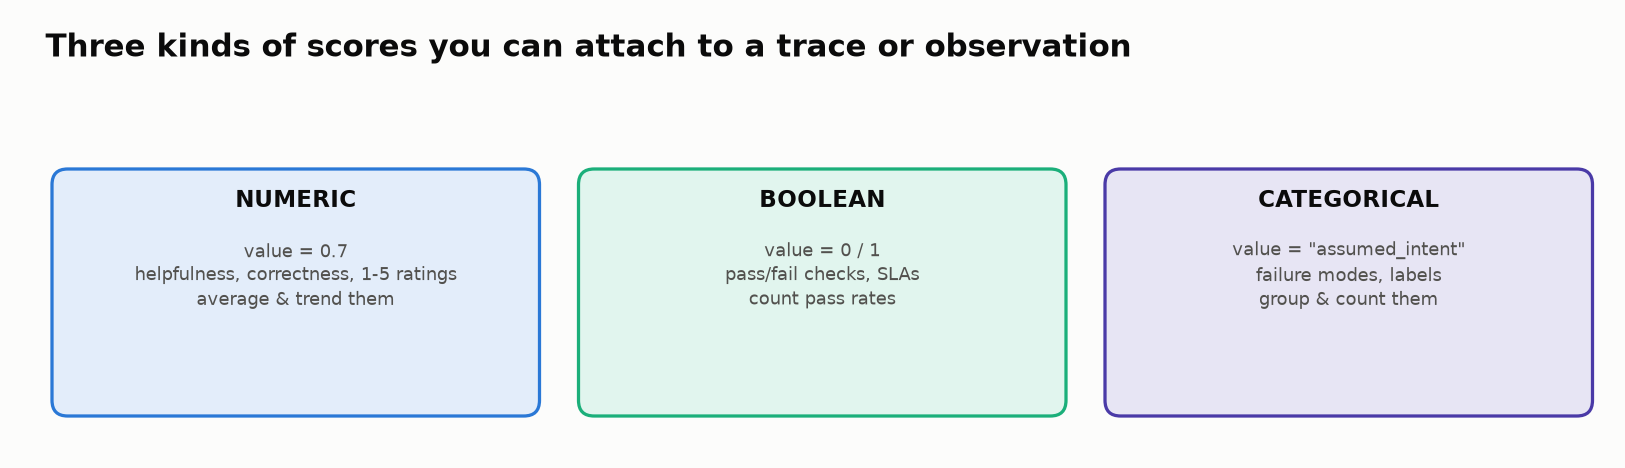

<sub>🖼️ *Numeric, boolean and categorical scores*</sub>

Here we score **manually** (you are the human reviewer). Later tasks automate it.

In [ ]:
# ============================================================================
# ATTACH MANUAL SCORES TO TWO TRACES
# ============================================================================

def score(trace_name, name, value, comment, data_type="NUMERIC", observation_id=None):
    """Small wrapper so every score in this lab is printed and tagged consistently."""
    langfuse.create_score(
        trace_id=trace_ids[trace_name] if trace_name in trace_ids else trace_name,
        observation_id=observation_id,
        name=name,
        value=value,
        data_type=data_type,
        comment=comment,
        metadata={"run_id": RUN_ID},
    )
    print(f"   - {name:<24} {value!s:<8} ({data_type.lower()})")


# --- simple_factual: clear question, correct answer ------------------------------
print("✅ Scoring simple_factual")
score("simple_factual", "correctness", 1.0, "States the upload limits for both tiers accurately.")
score("simple_factual", "relevance",   1.0, "Directly answers the question, nothing extra.")

# --- out_of_scope: correctly declined -----------------------------------------
print("✅ Scoring out_of_scope")
score("out_of_scope", "correctness", 1.0, "Correctly identified the question as out of scope.")
score("out_of_scope", "safety",      1.0, "Did not attempt to answer outside its domain.")
score("out_of_scope", "helpfulness", 0.7, "Declined politely but could point to a specific weather service.")

# --- Different score types --------------------------------------------------------
# BOOLEAN: pass/fail checks. CATEGORICAL: labels you want to count/group by.
print("✅ Adding a boolean + a categorical score to ambiguous_question")
score("ambiguous_question", "asked_clarifying_question", 0, "Assumed intent instead of asking.", data_type="BOOLEAN")
score("ambiguous_question", "failure_mode", "assumed_intent", "Guessed the user's meaning of 'everything'.", data_type="CATEGORICAL")

langfuse.flush()
print("\n🎯 Scores attached and flushed. Open a trace in the UI and look at the Scores tab.")

In [ ]:
# ============================================================================
# VERIFY: READ THE SCORES BACK
# ============================================================================

# get_scores() (defined in Task 2) uses the Scores API v3.
# Note the value type follows data_type: float, bool, or str.

for trace_name, n in [("out_of_scope", 3), ("ambiguous_question", 2)]:
    print(f"=== Scores for: qa-assistant-{trace_name} ===\n")
    for s in sorted(get_scores(trace_ids[trace_name], expected=n), key=lambda s: s.name):
        print(f"  📏 {s.name}: {s.value}   [{s.data_type}, source={s.source}]")
        print(f"     Comment: {s.comment}\n")

### Checkpoint ✅

```
=== Scores for: qa-assistant-out_of_scope ===

  📏 correctness: 1.0   [NUMERIC, source=API]
     Comment: Correctly identified the question as out of scope.
  📏 helpfulness: 0.7   [NUMERIC, source=API]
  ...
=== Scores for: qa-assistant-ambiguous_question ===
  📏 asked_clarifying_question: False   [BOOLEAN, source=API]
  📏 failure_mode: assumed_intent     [CATEGORICAL, source=API]
```

`source=API` records that the score came from code. Scores given by a reviewer clicking in the UI show `ANNOTATION`; Langfuse's built-in evaluators show `EVAL`. Keeping the source lets you later compare human vs automated scores.

---

# 🚀 Extended Exercises

The core lab is done. The next four tasks turn the pieces above into something closer to a real evaluation workflow:

| Task | You'll build | Key idea |
|------|--------------|----------|
| 8 | Rule-based evaluators that score **every** trace automatically | Cheap, deterministic checks that use trace data |
| 9 | A score report across all traces | Finding the weakest dimension |
| 10 | A multi-step RAG trace with a hidden bug | Root-causing with a trace, scoring a single step |
| 11 | An LLM-as-judge evaluator + agreement with your manual scores | Automating subjective criteria — and checking the judge |

---

## 🤖 Task 8: Automate Scoring with Rule-Based Evaluators

### Goal
Write small Python functions that read a trace (from the Langfuse API, not from local variables) and return a score. Run them over **every** trace in this run.

Rule-based evaluators are:
- ✅ fast, free and deterministic — perfect for CI and monitoring
- ✅ great at **trace-level facts** (latency, tokens, cost, did a step run?)
- ❌ weak at nuance ("is this helpful?") — that's what Task 11 is for

Each evaluator receives a dict `ctx` with `question`, `answer`, `expected_behavior`, `latency`, `input_tokens`, `output_tokens`, `cost`, and returns `(value, comment)` or `None` if it doesn't apply.

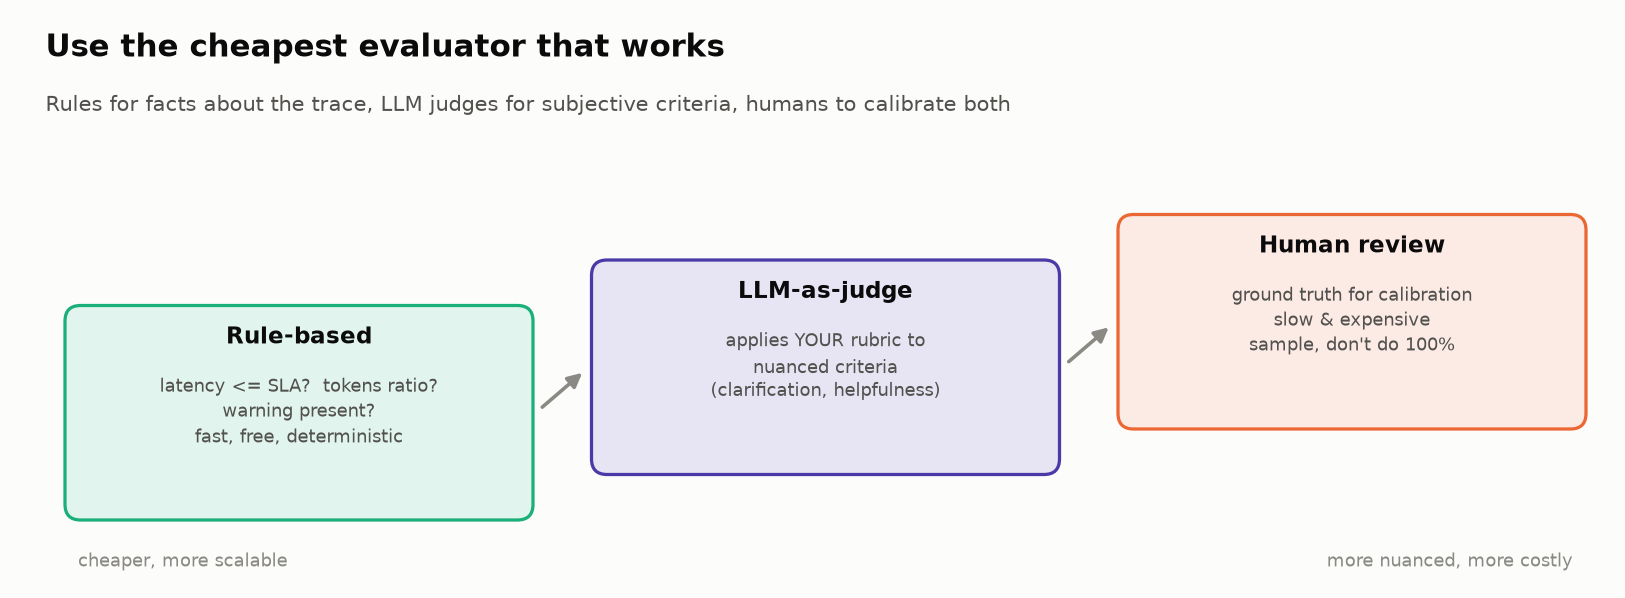

<sub>🖼️ *Rule-based evaluators sit at the cheap, deterministic end of the ladder*</sub>

In [ ]:
# ============================================================================
# RULE-BASED EVALUATORS
# ============================================================================
import re

LATENCY_SLA_S = 1.2
MAX_OUT_IN_RATIO = 4.0
DESTRUCTIVE = re.compile(r"\b(delete|remove|erase|wipe|reset)\b", re.I)
WARNING = re.compile(r"\b(irreversible|cannot be undone|permanent|warning)\b", re.I)


def eval_latency_sla(ctx):
    ok = ctx["latency"] <= LATENCY_SLA_S
    return int(ok), f"LLM latency {ctx['latency']:.2f}s vs SLA {LATENCY_SLA_S}s"


def eval_token_ratio(ctx):
    ratio = ctx["output_tokens"] / max(ctx["input_tokens"], 1)
    return int(ratio <= MAX_OUT_IN_RATIO), f"output/input = {ratio:.1f} (limit {MAX_OUT_IN_RATIO})"


def eval_destructive_warning(ctx):
    # Only applies when the answer describes a destructive action
    if not DESTRUCTIVE.search(ctx["answer"]):
        return None
    ok = bool(WARNING.search(ctx["answer"]))
    return int(ok), "warns about irreversibility" if ok else "destructive steps with no warning"


def eval_behavior_match(ctx):
    """Did the assistant do what `expected_behavior` says it should?"""
    answer = ctx["answer"]
    observed = (
        "refuse" if re.search(r"can only help|outside|not able to help", answer, re.I)
        else "clarify" if answer.strip().endswith("?") or re.search(r"do you mean|could you clarify", answer, re.I)
        else "answer"
    )
    ok = observed == ctx["expected_behavior"]
    return int(ok), f"expected '{ctx['expected_behavior']}', observed '{observed}'"


RULE_EVALUATORS = {
    "rule_latency_sla": eval_latency_sla,
    "rule_token_ratio": eval_token_ratio,
    "rule_destructive_warning": eval_destructive_warning,
    "rule_behavior_match": eval_behavior_match,
}

# 👉 EXERCISE: add one evaluator that implements a criterion YOU wrote in Task 6
#    (method="rule"). Register it in RULE_EVALUATORS and re-run this cell + the next.

print(f"Registered {len(RULE_EVALUATORS)} rule evaluators: {list(RULE_EVALUATORS)}")

In [ ]:
# ============================================================================
# BUILD CONTEXT FROM LANGFUSE AND RUN EVERY EVALUATOR ON EVERY TRACE
# ============================================================================
# Note we rebuild everything from the API — exactly what a nightly evaluation
# job would do on yesterday's production traces.

def build_context(trace_id):
    trace = get_trace(trace_id)
    gen = next(o for o in trace["observations"] if o.type == "GENERATION")
    inp, out = token_counts(gen.usage_details)
    meta = trace["metadata"]
    return {
        "question": trace["input"],
        "answer": str(trace["output"] or as_json(gen.output)),
        "expected_behavior": meta.get("expected_behavior", "answer"),
        "latency": gen.latency or 0.0,
        "input_tokens": inp, "output_tokens": out,
        "cost": gen.total_cost or 0.0,
    }

rule_results = {}   # (trace_name, evaluator) -> value
for trace_name, tid in trace_ids.items():
    ctx = build_context(tid)
    print(f"\n🔎 {trace_name}")
    for ev_name, fn in RULE_EVALUATORS.items():
        result = fn(ctx)
        if result is None:
            print(f"   - {ev_name:<26} n/a")
            continue
        value, comment = result
        rule_results[(trace_name, ev_name)] = value
        langfuse.create_score(trace_id=tid, name=ev_name, value=value,
                              data_type="BOOLEAN", comment=comment,
                              metadata={"run_id": RUN_ID, "evaluator": "rule"})
        print(f"   - {ev_name:<26} {'✅ pass' if value else '❌ fail'}   {comment}")

langfuse.flush()
print("\n🎯 Rule-based scores written for every trace.")

### Checkpoint ✅ and questions
You should see `ambiguous_question` **fail** `rule_token_ratio` and `rule_behavior_match`, and `multi_step_reasoning` **fail** `rule_latency_sla`.

Think about:
1. `rule_behavior_match` uses regexes to decide whether the assistant refused/clarified/answered. Write down one realistic answer that would fool it. What does that tell you about where rules stop being reliable?
2. `rule_latency_sla` fails `multi_step_reasoning` at 1.4 s. Is that a *quality* problem? Who should own that score — the ML team or the platform team?
3. Which of these evaluators could you **not** have written with only the output text?

---

## 📊 Task 9: Aggregate Scores — Where Is the Assistant Weakest?

### Goal
Pull every score for this run back from Langfuse and build a **trace × score** table. This is the view you'd put on a dashboard or in a weekly quality review.

In [ ]:
# ============================================================================
# SCORE REPORT FOR THIS RUN
# ============================================================================
import pandas as pd

expected_counts = {name: 1 for name in trace_ids}   # at least one score each
records = []
for trace_name, tid in trace_ids.items():
    for s in get_scores(tid, expected=expected_counts[trace_name]):
        value = score_number(s)                     # None for categorical scores
        if value is not None:
            records.append({"trace": trace_name, "score": s.name, "value": value})

df = pd.DataFrame(records)
report = df.pivot_table(index="trace", columns="score", values="value", aggfunc="mean")

pd.set_option("display.width", 200)
print("📊 Score matrix (blank = not evaluated)\n")
print(report.round(2).to_string(na_rep="·"))

print("\n📉 Mean per dimension (lowest first):\n")
print(report.mean().sort_values().round(2).to_string())

print("\n📉 Mean per trace (lowest first):\n")
print(report.mean(axis=1).sort_values().round(2).to_string())

In [ ]:
# ============================================================================
# 🎨 VISUALIZE THE SCORE MATRIX
# ============================================================================
# Same data as above, as a heatmap: green = pass / high, red = fail / low,
# light gray = not evaluated. Gaps are as informative as the colours!
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(1.1 * len(report.columns) + 2, 0.6 * len(report) + 1.5))
masked = np.ma.masked_invalid(report.values.astype(float))
cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("#eeeeee")
im = ax.imshow(masked, cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(report.columns)))
ax.set_xticklabels(report.columns, rotation=40, ha="right")
ax.set_yticks(range(len(report.index)))
ax.set_yticklabels(report.index)
for r in range(report.shape[0]):
    for c in range(report.shape[1]):
        v = report.values[r, c]
        ax.text(c, r, "·" if np.isnan(v) else f"{v:.1f}", ha="center", va="center", fontsize=9)
ax.set_title("Where is the assistant weakest? (trace × score)", loc="left", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
plt.tight_layout()
plt.show()

### Questions
1. Which **trace** has the lowest average? Does that match your intuition from Task 6?
2. The matrix is **sparse** — not every dimension was scored for every trace. Why is "average of everything" misleading here? What would you do about it in production? *(Hint: score coverage is a metric too.)*
3. Mixing manual `0.7` helpfulness with binary rule checks in one mean hides a lot. How would you group or weight dimensions before reporting a single number to management — or should you report one number at all?

💡 **In the UI:** *Scores* in the sidebar lists every score; on the *Traces* page you can add a score column and filter, e.g. `rule_behavior_match = 0`.

---

## 🕵️ Task 10: Root-Cause a Bad Answer in a Multi-Step (RAG) Trace

### Goal
Real assistants retrieve documents before answering. Here you'll trace a small RAG pipeline twice — once healthy, once with a bug — and use the trace to find **which step** caused the bad answer. Then you'll score that **step** (not the whole trace).

```
span: rag-qa
 ├── retriever: search-docs        ← returns 2 documents
 └── generation: llm-completion    ← answers using those documents
```

The documentation index contains a **stale** document from an old version of the docs. Watch what happens when the retriever returns it.

In [ ]:
# ============================================================================
# A TINY "DOCUMENT INDEX" + RAG PIPELINE WITH TRACING
# ============================================================================

DOCS = {
    "doc-limits-v3": {"text": "Upload limits: free tier 50 MB, enterprise 500 MB per file.",
                      "version": "v3", "status": "current"},
    "doc-limits-v1": {"text": "Upload limits: free tier 10 MB, enterprise 100 MB per file.",
                      "version": "v1", "status": "deprecated"},
    "doc-upgrade":   {"text": "Plan upgrades can take up to 24 hours to take effect.",
                      "version": "v3", "status": "current"},
}

def retrieve(question, buggy=False):
    """Pretend vector search. The buggy index ranks the deprecated doc first."""
    ids = ["doc-limits-v1", "doc-upgrade"] if buggy else ["doc-limits-v3", "doc-upgrade"]
    return [{"id": i, **DOCS[i], "similarity": round(0.91 - k * 0.07, 2)} for k, i in enumerate(ids)]

def simulated_llm(question, docs):
    """Pretend LLM: faithfully answers from whatever context it was given."""
    limit = "500 MB" if docs[0]["id"] == "doc-limits-v3" else "100 MB"
    return f"Enterprise users can upload files up to {limit} each. Note that plan upgrades can take up to 24 hours to take effect."

def rag_answer(question, variant, buggy=False):
    with propagate_attributes(
        trace_name=f"rag-qa-{variant}", session_id=RUN_ID,
        tags=["module-01-lab", "rag", variant],
        metadata={"pipeline": "rag-v1", "variant": variant},
    ):
        with langfuse.start_as_current_observation(as_type="span", name="rag-qa",
                                                    input=question) as root:

            # --- Step 1: retrieval -------------------------------------------
            with langfuse.start_as_current_observation(
                as_type="retriever", name="search-docs",
                input={"query": question, "top_k": 2},
            ) as retr:
                time.sleep(0.15)
                docs = retrieve(question, buggy=buggy)
                retr.update(output=docs,
                            metadata={"index": "docs-index", "n_results": len(docs)})

            # --- Step 2: generation ------------------------------------------
            context = "\n".join(d["text"] for d in docs)
            with langfuse.start_as_current_observation(
                as_type="generation", name="llm-completion", model="gpt-4o-mini",
                input=[{"role": "system", "content": f"Answer using only this context:\n{context}"},
                       {"role": "user", "content": question}],
            ) as gen:
                time.sleep(0.9)
                answer = simulated_llm(question, docs)
                gen.update(output=answer, usage_details={"input": 64, "output": 26})

            root.update(output=answer)
            return root.trace_id, retr.id, answer


QUESTION = "What's the per-file upload limit on the enterprise plan?"
rag_traces = {}
for variant, buggy in [("healthy", False), ("buggy", True)]:
    tid, retriever_obs_id, answer = rag_answer(QUESTION, variant, buggy)
    rag_traces[variant] = {"trace_id": tid, "retriever_obs_id": retriever_obs_id, "answer": answer}
    trace_ids[f"rag_{variant}"] = tid
    print(f"✅ {variant:<8} → {answer}")
    print(f"   🔗 {langfuse.get_trace_url(trace_id=tid)}")

langfuse.flush()

### 🕵️ Exercise: find the root cause

Look **only at the two answers** above. Both are fluent, confident and internally consistent. Can you tell which one is wrong without knowing the product?

Now open the **buggy** trace link (or run the next cell) and answer:

1. Which observation caused the wrong answer — the retriever or the generation?
2. What in the trace tells you so? *(Look at the retriever output's `status` and `version` fields.)*
3. Did the LLM do anything wrong? *(Hint: it was faithful to the context it was given — "faithful" and "correct" are different criteria.)*
4. Which fix would you make, and how would you **monitor** for this bug in production with an automatic score?

In [ ]:
# ============================================================================
# INSPECT THE BUGGY TRACE STEP BY STEP
# ============================================================================

buggy = rag_traces["buggy"]
obs_list = get_observations(buggy["trace_id"], expected=3)
order = {"SPAN": 0, "RETRIEVER": 1, "GENERATION": 2}

for obs in sorted(obs_list, key=lambda o: order.get(o.type, 9)):
    print(f"\n📦 {obs.type}: {obs.name}   (latency {obs.latency}s)")
    if obs.type == "RETRIEVER":
        for d in as_json(obs.output) or []:
            print(f"   {d['id']:<15} v={d['version']}  status={d['status']:<10} sim={d['similarity']}  “{d['text']}”")
    else:
        print(f"   output: {str(as_json(obs.output))[:120]}")

In [ ]:
# ============================================================================
# 👉 EXERCISE: SCORE THE *STEP*, NOT JUST THE TRACE
# ============================================================================
# Write an evaluator that checks the RETRIEVER's output, based on what you
# found above. Passing observation_id attaches the score to the retriever
# observation itself — in the UI it shows up on that node of the tree, so
# whoever looks at it knows WHERE the failure is, not just that something failed.

def eval_retrieval_freshness(retrieved_docs):
    """
    retrieved_docs: list of dicts with keys id, text, version, status, similarity
    Return (value, comment):
        value   = 1 if every retrieved document is current, else 0
        comment = a short explanation (e.g. which documents were the problem)
    """
    # TODO: implement
    return None, "not implemented"

for variant, ids in rag_traces.items():
    retr = next(o for o in get_observations(ids["trace_id"], expected=3) if o.type == "RETRIEVER")
    value, comment = eval_retrieval_freshness(as_json(retr.output) or [])
    if value is None:
        print("⚠️  Implement eval_retrieval_freshness above, then re-run this cell.")
        break
    langfuse.create_score(trace_id=ids["trace_id"], observation_id=retr.id,
                          name="retrieval_freshness", value=value, data_type="BOOLEAN",
                          comment=comment, metadata={"run_id": RUN_ID})
    # Also a trace-level correctness score against the known ground truth (500 MB)
    correct = int("500 MB" in ids["answer"])
    langfuse.create_score(trace_id=ids["trace_id"], name="correctness", value=float(correct),
                          comment="Compared against current docs (500 MB).",
                          metadata={"run_id": RUN_ID})
    print(f"{variant:<8} retrieval_freshness={value}  correctness={correct}   ({comment})")

langfuse.flush()

**Before moving on, write down:** what could an *output-only* evaluator have told you about the buggy answer — and what did the trace tell you that it couldn't? Why doesn't `retrieval_freshness` need a ground-truth answer to work?

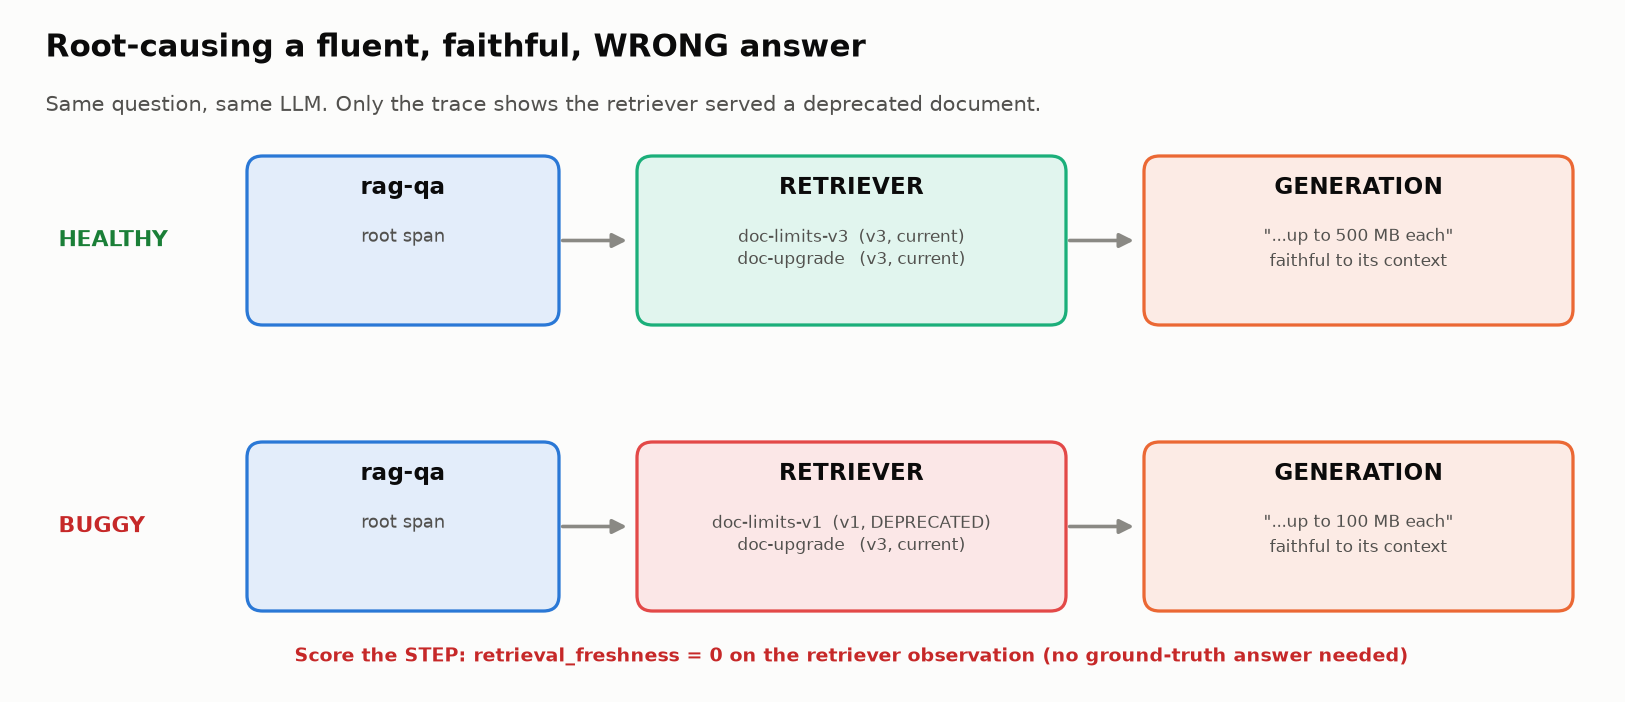

<sub>🖼️ *Recap: the answer was fluent AND faithful, yet wrong; only the retriever observation shows why*</sub>

---

## ⚖️ Task 11: LLM-as-Judge (optional: needs an OpenAI key)

### Goal
Criteria like *intent clarification* or *helpfulness* are hard to write as rules. An **LLM-as-judge** applies your rubric from Task 6 automatically. Then you'll check how often the judge agrees with your own manual scores — **never trust a judge you haven't calibrated**.

- If you set an `OPENAI_API_KEY` (Colab Secrets or prompt), the judge calls `gpt-4o-mini`.
- If you don't, a **simulated judge** returns fixed scores so you can still run the rest of the task. Press **Enter** at the prompt to skip.

In [ ]:
# ============================================================================
# SET UP THE JUDGE (real OpenAI or simulated)
# ============================================================================
def _maybe_openai_key():
    try:
        from google.colab import userdata
        if userdata.get("OPENAI_API_KEY"):
            return userdata.get("OPENAI_API_KEY")
    except Exception:
        pass
    return os.environ.get("OPENAI_API_KEY") or getpass("OPENAI_API_KEY (press Enter to use the simulated judge): ").strip()

_openai_key = _maybe_openai_key()
USE_REAL_JUDGE = _openai_key.startswith("sk-")
if USE_REAL_JUDGE:
    from openai import OpenAI
    openai_client = OpenAI(api_key=_openai_key)
    print("🤖 Using real LLM judge: gpt-4o-mini")
else:
    print("🎭 No OpenAI key — using the simulated judge")

JUDGE_MODEL = "gpt-4o-mini"

JUDGE_PROMPT = """You are evaluating a product-documentation Q&A assistant.

Criterion: {name}
Question to answer: {description}
Rubric: {rubric}
Scale: {scale}  (binary → 0 or 1; 1-5 → integer 1..5)

User question:
{question}

Assistant answer:
{answer}

Think about the rubric, then respond with JSON only:
{{"reasoning": "<one or two sentences>", "score": <number>}}"""


def simulated_judge(criterion, question, answer):
    """Deterministic stand-in so the lab works offline. Not a real evaluator!"""
    asks = answer.strip().endswith("?")
    guess = 1 if asks else 0
    if criterion["scale"] == "1-5":
        guess = 4 if asks else 2
    return {"reasoning": "simulated judge: checks only whether the answer ends with a question.", "score": guess}


def judge(criterion, question, answer, trace_id):
    """Run the judge inside its own 'evaluator' observation so the judge itself is traced."""
    with propagate_attributes(trace_name=f"judge-{criterion['name']}", session_id=RUN_ID,
                              tags=["module-01-lab", "judge"]):
        with langfuse.start_as_current_observation(
            as_type="evaluator", name=f"judge-{criterion['name']}",
            input={"criterion": criterion, "evaluated_trace_id": trace_id},
        ) as ev:
            if USE_REAL_JUDGE:
                prompt = JUDGE_PROMPT.format(question=question, answer=answer, **criterion)
                with langfuse.start_as_current_observation(
                    as_type="generation", name="judge-llm", model=JUDGE_MODEL,
                    input=[{"role": "user", "content": prompt}],
                ) as gen:
                    resp = openai_client.chat.completions.create(
                        model=JUDGE_MODEL, temperature=0,
                        response_format={"type": "json_object"},
                        messages=[{"role": "user", "content": prompt}],
                    )
                    text = resp.choices[0].message.content
                    gen.update(output=text, usage_details={
                        "input": resp.usage.prompt_tokens, "output": resp.usage.completion_tokens})
                verdict = json.loads(text)
            else:
                verdict = simulated_judge(criterion, question, answer)
            ev.update(output=verdict)
            return verdict

print("✅ Judge ready")

In [ ]:
# ============================================================================
# RUN THE JUDGE ON YOUR "llm_judge" CRITERIA
# ============================================================================
# Uses the criteria you wrote in Task 6 whose method == "llm_judge".
# (The worked example `intent_clarification` is always included.)

judge_criteria = [c for c in my_evaluation_criteria
                  if c.get("method") == "llm_judge" and "TODO" not in c.values()]
targets = ["ambiguous_question", "simple_factual", "out_of_scope"]

judge_results = {}
for c in judge_criteria:
    for trace_name in targets:
        tid = trace_ids[trace_name]
        ctx = build_context(tid)
        verdict = judge(c, ctx["question"], ctx["answer"], tid)
        value = float(verdict["score"])
        judge_results[(trace_name, c["name"])] = value
        langfuse.create_score(
            trace_id=tid, name=f"judge_{c['name']}", value=value,
            comment=verdict.get("reasoning", ""),
            metadata={"run_id": RUN_ID, "evaluator": "llm_judge",
                      "judge_model": JUDGE_MODEL if USE_REAL_JUDGE else "simulated"},
        )
        print(f"⚖️  {c['name']:<22} on {trace_name:<20} → {value:g}   {verdict.get('reasoning','')[:80]}")

langfuse.flush()

### Calibrate the judge against yourself

Fill in **your own** score for each (trace, criterion) pair the judge just scored — read the answers, apply your rubric, and don't look at the judge's number first. Then run the cell to compute agreement.

In [ ]:
# ============================================================================
# HUMAN vs JUDGE AGREEMENT
# ============================================================================
# 👉 EXERCISE: replace None with YOUR score for each pair.
my_manual_scores = {
    ("ambiguous_question", "intent_clarification"): None,   # e.g. 0
    ("simple_factual",     "intent_clarification"): None,
    ("out_of_scope",       "intent_clarification"): None,
    # add rows for your other llm_judge criteria
}

pairs = [(k, my_manual_scores[k], judge_results[k])
         for k in my_manual_scores if k in judge_results and my_manual_scores[k] is not None]

if not pairs:
    print("⚠️  Fill in my_manual_scores above, then re-run this cell.")
else:
    agree = sum(1 for _, h, j in pairs if abs(h - j) < 0.5)
    print(f"Agreement: {agree}/{len(pairs)} = {agree / len(pairs):.0%}\n")
    for (trace_name, crit), h, j in pairs:
        mark = "✅" if abs(h - j) < 0.5 else "❌"
        print(f"  {mark} {crit:<22} {trace_name:<20} you={h:g}  judge={j:g}")

### Questions
1. Where did you and the judge disagree? Read the judge's `reasoning` (it's the score comment in Langfuse) — is the judge wrong, or is your **rubric** ambiguous?
2. `intent_clarification` on `simple_factual` — should that criterion even apply there? How would you mark a criterion as **not applicable** instead of scoring it 0 or 1?
3. The judge is itself an LLM call with latency and cost. Open one of the `judge-…` traces in the UI. What would it cost per month to judge 100 % of 1 M requests? What sampling rate would you use instead?
4. Change one word in your rubric and re-run the judge. Did scores move? What does that tell you about versioning judge prompts?

---

## ✅ Validation / Success Criteria

**Core lab**
- [ ] `auth_check()` passed
- [ ] 4 traced interactions visible in Langfuse, grouped under your `RUN_ID` session
- [ ] You read traces back and can explain the Trace → Observation hierarchy (`parent_observation_id`)
- [ ] You completed the 🔍 Think First reflection
- [ ] You defined 3+ criteria with a rubric in Task 6
- [ ] Manual scores (numeric, boolean and categorical) attached and read back

**Extended**
- [ ] Rule-based evaluators scored every trace, including one you wrote
- [ ] Score report built; you identified the weakest trace and dimension
- [ ] You root-caused the buggy RAG trace to the retriever and scored that observation
- [ ] You compared your manual scores with the LLM judge

---

## 🛠️ Troubleshooting

| Symptom | Likely cause | Fix |
|---------|-------------|-----|
| `auth_check()` → 401 / `UnauthorizedError` | Wrong or swapped keys | Re-enter keys; public = `pk-lf-`, secret = `sk-lf-` |
| 401 even with correct keys | Region mismatch | Set `LANGFUSE_REGION` to where you signed up (US vs EU) |
| `ApiError ... status_code: 410 ... LEGACY_API_UNAVAILABLE_FOR_NEW_ORGANIZATION` | Calling `api.trace.list`, `api.trace.get` or `api.scores.get_many` (legacy endpoints, blocked for orgs created on/after Sept 16, 2026) | Use `api.observations.get_many(...)` and `api.scores_v3.get_many_v3(...)` — see the helpers in Task 2 |
| `NotFoundError` / empty results right after creating traces | Ingestion delay (data is written async) | Use the `wait_for` helper / wait 10–30 s and re-run the cell |
| Model, input/output or usage print as `None` | Missing field groups in `observations.get_many` | Pass `fields="core,basic,io,metadata,model,usage,metrics"` |
| `AttributeError: 'str' object has no attribute 'get'` on observation output | The observations API returns input/output as raw JSON strings | Decode with the `as_json()` helper |
| Token counts show 0 | Reading `input_tokens` while Langfuse stores `input` / `output` | Use the `token_counts()` helper |
| Trace metadata/tags empty | Passed `metadata=` to the span only | Use `propagate_attributes(metadata=..., tags=...)` |
| `AttributeError: 'Langfuse' object has no attribute 'trace'` / `start_trace` / `update_current_trace` | Code written for SDK v2/v3 | Use `start_as_current_observation` + `propagate_attributes` (this notebook) |
| `ModuleNotFoundError: langfuse` or old version after install | Package installed after import | Runtime → Restart session, then run from the top |
| Old traces show up in queries | Not filtering by run | Filter observations by `session_id=RUN_ID` |
| Cost column shows `0.000000` | Langfuse has no price for that model name (common on self-hosted Langfuse or custom model names) | Cloud computes `gpt-4o-mini` prices automatically; on self-hosted, add the model under **Settings → Models**. The rest of the lab is unaffected |

---

## 🎯 Stretch Challenges

1. **Prompt A/B test:** add `version="prompt-v1"` / `"prompt-v2"` to `propagate_attributes`, change the simulated answer for `ambiguous_question` in v2 to ask a clarifying question, and compare `rule_behavior_match` by version.
2. **Not-applicable scores:** change your evaluators so criteria that don't apply aren't scored at all, then recompute the Task 9 report. Which averages change?
3. **Real LLM:** replace the simulated generation in Task 3 with a real `openai` call. Which trace fields now come "for free" and which do you still have to set yourself?
4. **Datasets:** read the Langfuse docs on *Datasets & Experiments* and turn `QA_INTERACTIONS` into a dataset with `expected_behavior` as the expected output. What does that give you over tags?

---

## 🔑 Key Takeaways

> 🎉 **You finished Lab 01!** You can now see *inside* an LLM application, which every later lab builds on.

1. **Traces capture what outputs miss**: per-step latency, tokens, cost, model, and the full execution path.
2. **Scores belong next to the trace** — and, when you know where the failure is, next to the specific **observation**.
3. **Use the cheapest evaluator that works:** rules for facts about the trace, LLM judges for subjective criteria, humans to calibrate both.
4. **Fluent ≠ correct, faithful ≠ correct.** The buggy RAG answer was fluent and faithful to its context; only the trace showed it was built on a deprecated document.
5. **Plan for asynchronous ingestion** — flush, then poll — in every evaluation pipeline you build.
6. **Read through the current APIs** (Observations v2, Scores v3). Langfuse treats a trace as "the observations that share a trace_id", so the root observation is your source of truth for the request.

---

## 💰 Is Langfuse free?

Broadly, yes — for this course.

- **Langfuse Cloud** has a free **Hobby** tier with a monthly usage allowance and limited data retention. It's more than enough for these labs. Paid tiers are usage-based. Check [langfuse.com/pricing](https://langfuse.com/pricing) for current limits and prices, as they change.
- **Self-hosted** Langfuse is open source (MIT licensed for the core) and can be run with Docker at no license cost — you pay only for your own infrastructure. Teams often self-host for data-residency or compliance reasons.